# ClimaSkin — Part 2, Questions 1–3

In [7]:
import matplotlib.pyplot as plt
import numpy as np
import numpy_financial as npf

MILLION = 1_000_000

## Question 1 — Net cash flows and NPV
**Task:** input $(\lambda,g,\ell,P,\tau,r)$ and return $(c_t)_{t=0}^{25}$ and NPV.

| Item | Calculation |
| :--- | :--- |
| Net operating income | $\mathrm{NOI}_t=R_t+F_t-K_t-L_t$ |
| Less depreciation → taxable income | $\mathrm{NOI}_t-D$ |
| Less taxes → net income | $(1-\tau)(\mathrm{NOI}_t-D)$ |
| Add back depreciation → net cash flow | $c_t=(1-\tau)(\mathrm{NOI}_t-D)+D=(1-\tau)\mathrm{NOI}_t+\tau D$ |

$$\mathrm{NPV}=-I_0+\sum_{t=1}^{25}\frac{c_t}{(1+r)^t}.$$
Invest when NPV is positive; be indifferent at zero; do not invest when negative.

**Assumptions:** deductions and production losses offset other profits immediately; no tax on startup or land resale, so $V_{\mathrm{land,net}}=\$1.5\mathrm{mm}$ (land tax basis unspecified); no terminal sale receipts in year 25.

In [8]:
def climaskin(lam, g, ell, P, tau, r, *, V_land_net=1.5 * MILLION):
    """Return net cash flows c[t] for years 0-25 and NPV, in dollars."""
    # Project assumptions.
    development_years = 5
    plant_lifetime = 20
    monopoly_years = 5
    annual_rd_cost = 22 * MILLION
    plant_cost = 95 * MILLION
    initial_units = 30_000
    annual_unit_increase = 3_000
    initial_price = 10_000
    initial_component_cost = 5_500
    initial_labor_marketing_cost = 20 * MILLION
    annual_licensing_revenue = 30 * MILLION

    # Derive the timeline.
    construction_year = development_years
    production_start = construction_year + 1
    licensing_start = production_start + monopoly_years
    final_year = construction_year + plant_lifetime
    t = np.arange(production_start, final_year + 1)
    years_since_production = t - production_start
    price_decline_periods = np.maximum(t - licensing_start + 1, 0)

    q_t = initial_units + annual_unit_increase * years_since_production
    p_t = initial_price * (1 - lam) ** price_decline_periods
    k_t = initial_component_cost * (1 + g) ** years_since_production
    L_t = initial_labor_marketing_cost * (1 + ell) ** years_since_production
    F_t = np.where(t >= licensing_start, annual_licensing_revenue, 0)
    D = plant_cost / plant_lifetime

    # Order: sales -> NOI -> taxable income -> net income -> net cash flow.
    R_t = q_t * p_t
    K_t = q_t * k_t
    NOI_t = R_t + F_t - K_t - L_t
    taxable_income = NOI_t - D
    taxes = tau * taxable_income
    net_income = taxable_income - taxes

    I_0 = P + V_land_net
    c = np.zeros(final_year + 1)
    c[0] = -I_0  # Resale opportunities forgone.
    c[1:production_start] = -annual_rd_cost * (1 - tau)
    c[construction_year] -= plant_cost
    c[production_start:] = net_income + D  # Add back noncash depreciation.

    return c, npf.npv(r, c)

## Question 2 — Condition on the resale price $P$
**Given:** $g=\ell=\lambda=0.02$, $\tau=0.30$, $r=0.08$.

Only $c_0=-I_0$ depends on $P$: $\mathrm{NPV}(P)=\mathrm{NPV}(0)-P$. Thus $P^*=\mathrm{NPV}(0)$.

Invest if $P<P^*$; do not invest if $P>P^*$; be indifferent at equality. The graph shows **net cash flows $c_t$** at $P=P^*$, including $c_0=-(P^*+V_{\mathrm{land,net}})$. The bars are undiscounted. their simple sum is NOT zero. Their discounted sum at $r=8\%$ is zero.

In [9]:
c_q2_P0, P_star = climaskin(
    lam=0.02, g=0.02, ell=0.02, P=0, tau=0.30, r=0.08,
)
print(f"Invest if P < ${P_star / MILLION:,.3f}mm.")
print("At equality, TNF is indifferent; above the threshold, do not invest.")

Invest if P < $439.458mm.
At equality, TNF is indifferent; above the threshold, do not invest.


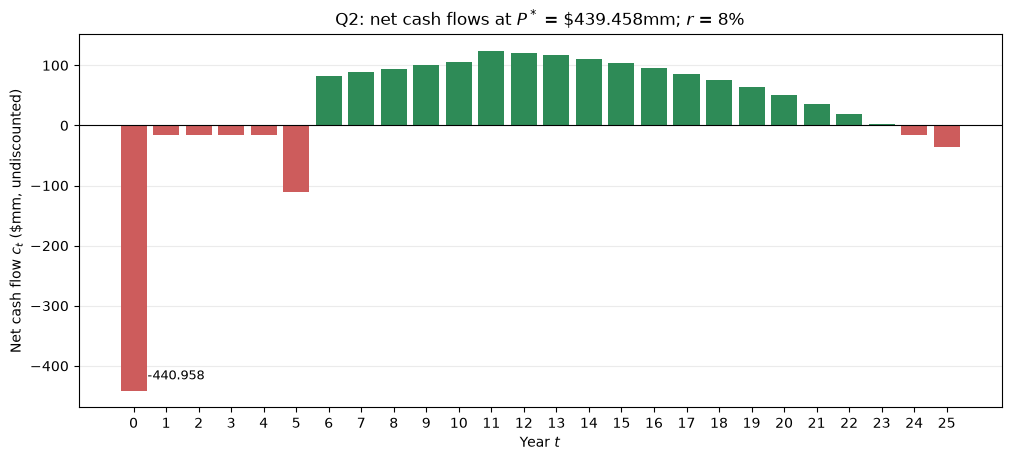

In [10]:
c_q2_at_threshold = c_q2_P0.copy()
c_q2_at_threshold[0] -= P_star
t = np.arange(len(c_q2_at_threshold))
flows = c_q2_at_threshold / MILLION
fig, ax = plt.subplots(figsize=(10, 4.5), layout="constrained")
ax.bar(t, flows, color=np.where(flows >= 0, "seagreen", "indianred"))
ax.axhline(0, color="black", linewidth=0.8)
ax.set(
    title=rf"Q2: net cash flows at $P^*$ = \${P_star / MILLION:,.3f}mm; $r$ = 8%",
    xlabel=r"Year $t$", ylabel=r"Net cash flow $c_t$ (\$mm, undiscounted)", xticks=t,
)
ax.annotate(
    f"{flows[0]:,.3f}", xy=(0, flows[0]), xytext=(10, 8),
    textcoords="offset points", fontsize=9,
)
ax.set_axisbelow(True)
ax.grid(axis="y", alpha=0.25)
plt.show()

## Question 3 — Condition on the opportunity cost of capital $r$
**Given:** $g=\ell=0.02$, $\lambda=0.01$, $\tau=0.35$, $P=\$1{,}000\mathrm{mm}$.

Find $r^*$ such that $\mathrm{NPV}(r^*)=0$. For $r\geq0$, invest if $r<r^*$; do not invest if $r>r^*$; be indifferent at equality.

The function's temporary `r=0` only affects the discarded NPV. The graph shows **net cash flows $c_t$**, which do not depend on $r$. Their present values $c_t/(1+r^*)^t$, including $c_0=-I_0$, sum to zero.

In [11]:
c_q3, _ = climaskin(
    lam=0.01, g=0.02, ell=0.02, P=1_000 * MILLION, tau=0.35, r=0,
)
r_star = npf.irr(c_q3)
print(f"Invest if r < {r_star:.6%} (for r >= 0).")
print("At equality, TNF is indifferent; above the threshold, do not invest.")

Invest if r < 3.281832% (for r >= 0).
At equality, TNF is indifferent; above the threshold, do not invest.


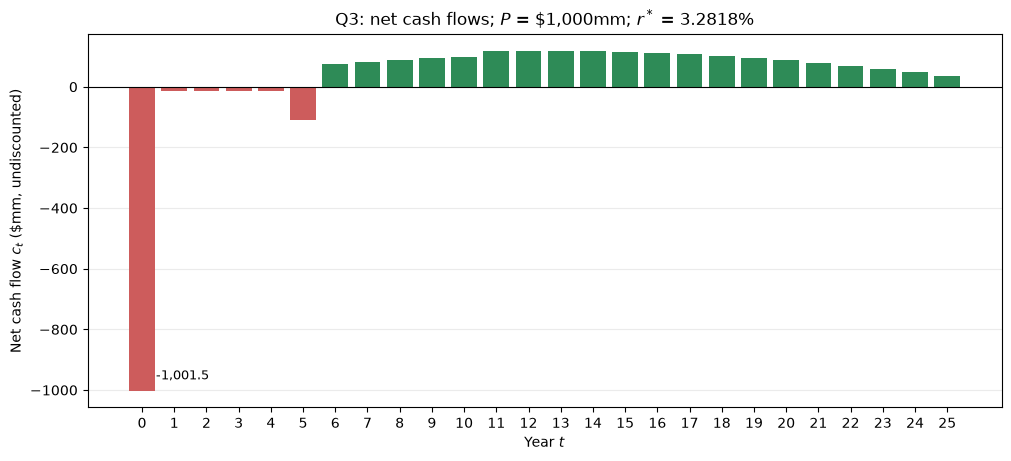

In [12]:
t = np.arange(len(c_q3))
flows = c_q3 / MILLION
fig, ax = plt.subplots(figsize=(10, 4.5), layout="constrained")
ax.bar(t, flows, color=np.where(flows >= 0, "seagreen", "indianred"))
ax.axhline(0, color="black", linewidth=0.8)
ax.set(
    title=rf"Q3: net cash flows; $P$ = \$1,000mm; $r^*$ = {r_star:.4%}",
    xlabel=r"Year $t$", ylabel=r"Net cash flow $c_t$ (\$mm, undiscounted)", xticks=t,
)
ax.annotate(
    f"{flows[0]:,.1f}", xy=(0, flows[0]), xytext=(10, 8),
    textcoords="offset points", fontsize=9,
)
ax.set_axisbelow(True)
ax.grid(axis="y", alpha=0.25)
plt.show()